Implement LIME to explain individual predictions by constructing synthetic perturbed datasets, training surrogate models manually, and validating explanations through independent verification techniques.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_absolute_error, r2_score

df = pd.read_csv("heart_disease_train.csv")

features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
target = "target"

for col in features + [target]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=features + [target]).copy()

X = df[features]
y = df[target].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

print("Model trained successfully.")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model trained successfully.
Training samples: 63
Testing samples: 16


In [2]:
patient_index = 0

patient = X_test.iloc[patient_index].copy()
actual_class = y_test.iloc[patient_index]

patient_df = patient.to_frame().T

original_probability = model.predict_proba(patient_df)[0, 1]
original_prediction = model.predict(patient_df)[0]

print("Patient features:")
print(patient)

print("\nActual class:", actual_class)
print("Predicted class:", original_prediction)
print("Probability of class 1:", round(original_probability, 4))

Patient features:
age          31.0
trestbps    134.0
chol        255.0
thalach     174.0
oldpeak       4.1
Name: 49, dtype: float64

Actual class: 0
Predicted class: 0
Probability of class 1: 0.33


In [3]:
def generate_perturbations(patient, n_samples=5000, seed=42):
    rng = np.random.default_rng(seed)

    train_mean = X_train.mean().values
    train_std = X_train.std().values
    train_std = np.where(train_std == 0, 1.0, train_std)

    patient_values = patient[features].values.astype(float)

    noise = rng.normal(
        loc=0,
        scale=1,
        size=(n_samples, len(features))
    )

    perturbed_values = patient_values + noise * train_std

    # Keep generated feature values within the training data ranges.
    lower_bounds = X_train.min().values
    upper_bounds = X_train.max().values

    perturbed_values = np.clip(
        perturbed_values,
        lower_bounds,
        upper_bounds
    )

    perturbed_df = pd.DataFrame(
        perturbed_values,
        columns=features
    )

    return perturbed_df

synthetic_data = generate_perturbations(patient)

synthetic_probabilities = model.predict_proba(
    synthetic_data
)[:, 1]

print("Synthetic samples:", len(synthetic_data))
print("Synthetic predictions calculated.")
print(synthetic_data.head())

Synthetic samples: 5000
Synthetic predictions calculated.
         age    trestbps        chol    thalach   oldpeak
0  35.528801  100.097386  353.950837  201.00000  0.739175
1  29.000000  138.167490  213.301793  173.40965  2.630559
2  44.069889  159.355368  263.706486  201.00000  4.905325
3  29.000000  146.020968  134.000000  201.00000  4.013998
4  29.000000  111.802265  416.198342  168.57023  3.362169


In [4]:
def fit_manual_lime(
    patient,
    synthetic_data,
    synthetic_probabilities
):
    train_mean = X_train.mean().values
    train_std = X_train.std().values
    train_std = np.where(train_std == 0, 1.0, train_std)

    patient_values = patient[features].values.astype(float)

    # Standardize the synthetic data and selected patient.
    Z = (synthetic_data.values - train_mean) / train_std
    z_patient = (patient_values - train_mean) / train_std

    # Measure distance from each synthetic sample to the patient.
    distances = np.sqrt(
        np.sum((Z - z_patient) ** 2, axis=1)
    )

    kernel_width = 0.75 * np.sqrt(len(features))

    weights = np.exp(
        -(distances ** 2) / (kernel_width ** 2)
    )

    # Add an intercept column to the surrogate model.
    design_matrix = np.column_stack([
        np.ones(len(Z)),
        Z
    ])

    W = np.diag(weights)

    # Weighted ridge regression, implemented manually.
    penalty = np.eye(design_matrix.shape[1]) * 1.0
    penalty[0, 0] = 0.0

    coefficients = np.linalg.solve(
        design_matrix.T @ W @ design_matrix + penalty,
        design_matrix.T @ W @ synthetic_probabilities
    )

    local_prediction = (
        coefficients[0] + np.dot(coefficients[1:], z_patient)
    )

    feature_contributions = coefficients[1:] * z_patient

    explanation = pd.DataFrame({
        "Feature": features,
        "Patient Value": patient_values,
        "Contribution": feature_contributions,
        "Coefficient": coefficients[1:]
    })

    explanation["Absolute Contribution"] = (
        explanation["Contribution"].abs()
    )

    explanation = explanation.sort_values(
        "Absolute Contribution",
        ascending=False
    )

    return coefficients, explanation, weights, z_patient

coefficients, explanation, weights, z_patient = fit_manual_lime(
    patient,
    synthetic_data,
    synthetic_probabilities
)

print(explanation.to_string(index=False))

 Feature  Patient Value  Contribution  Coefficient  Absolute Contribution
     age           31.0     -0.325926     0.221944               0.325926
    chol          255.0     -0.096087     0.134307               0.096087
trestbps          134.0     -0.051361     0.104232               0.051361
 thalach          174.0      0.011031     0.014526               0.011031
 oldpeak            4.1      0.000860     0.001574               0.000860


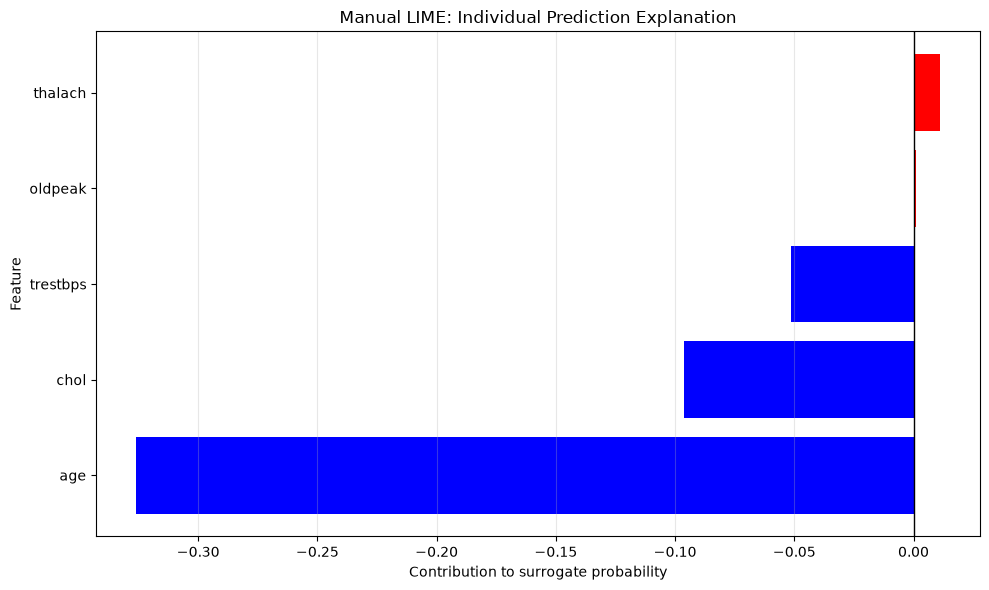

In [5]:
plot_df = explanation.sort_values("Contribution")

plt.figure(figsize=(10, 6))

bar_colors = [
    "red" if value > 0 else "blue"
    for value in plot_df["Contribution"]
]

plt.barh(
    plot_df["Feature"],
    plot_df["Contribution"],
    color=bar_colors
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Contribution to surrogate probability")
plt.ylabel("Feature")
plt.title("Manual LIME: Individual Prediction Explanation")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
validation_data = generate_perturbations(
    patient,
    n_samples=2000,
    seed=123
)

validation_probabilities = model.predict_proba(
    validation_data
)[:, 1]

train_mean = X_train.mean().values
train_std = X_train.std().values
train_std = np.where(train_std == 0, 1.0, train_std)

Z_validation = (
    validation_data.values - train_mean
) / train_std

validation_design = np.column_stack([
    np.ones(len(Z_validation)),
    Z_validation
])

surrogate_validation_predictions = (
    validation_design @ coefficients
)

# Measure local fidelity, giving more weight to nearby samples.
patient_values = patient[features].values.astype(float)
z_patient = (patient_values - train_mean) / train_std

distances = np.sqrt(
    np.sum((Z_validation - z_patient) ** 2, axis=1)
)

kernel_width = 0.75 * np.sqrt(len(features))

validation_weights = np.exp(
    -(distances ** 2) / (kernel_width ** 2)
)

weighted_mae = np.average(
    np.abs(
        validation_probabilities - surrogate_validation_predictions
    ),
    weights=validation_weights
)

weighted_r2 = 1 - (
    np.sum(
        validation_weights
        * (validation_probabilities - surrogate_validation_predictions) ** 2
    )
    /
    np.sum(
        validation_weights
        * (validation_probabilities - np.average(
            validation_probabilities,
            weights=validation_weights
        )) ** 2
    )
)

print("Independent validation results")
print("Weighted MAE:", round(weighted_mae, 4))
print("Weighted R²:", round(weighted_r2, 4))

Independent validation results
Weighted MAE: 0.0866
Weighted R²: 0.6857


          Mean Contribution  Contribution Std  Mean Absolute Contribution
age                -0.33964           0.00722                     0.33964
chol               -0.09494           0.00250                     0.09494
trestbps           -0.05012           0.00204                     0.05012
thalach             0.00702           0.00331                     0.00702
oldpeak            -0.00007           0.00214                     0.00171


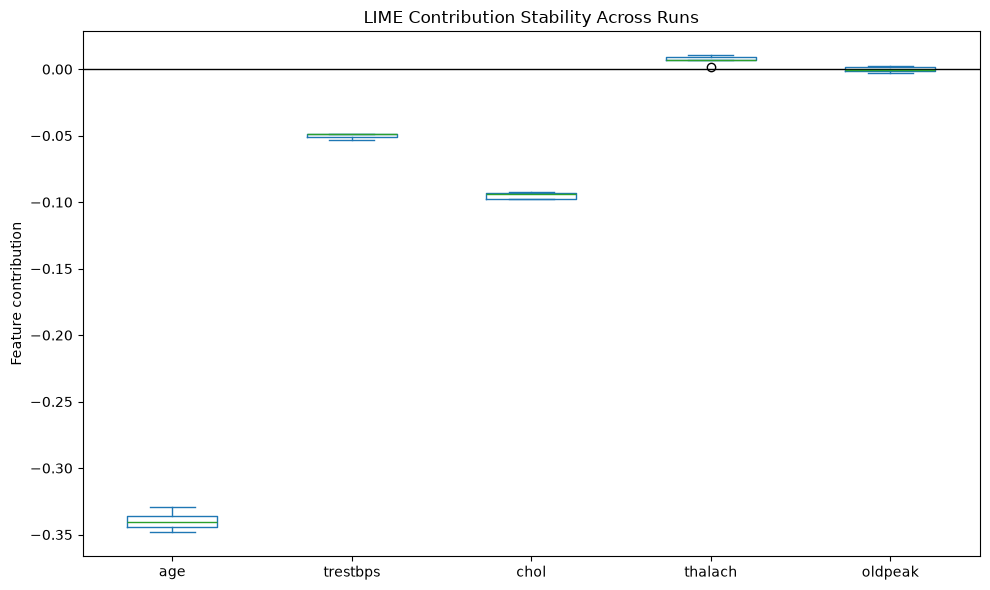

In [7]:
repeated_contributions = []

for seed in [10, 20, 30, 40, 50]:
    perturbed = generate_perturbations(
        patient,
        n_samples=3000,
        seed=seed
    )

    probabilities = model.predict_proba(perturbed)[:, 1]

    _, repeat_explanation, _, _ = fit_manual_lime(
        patient,
        perturbed,
        probabilities
    )

    contribution_map = repeat_explanation.set_index(
        "Feature"
    )["Contribution"]

    repeated_contributions.append(
        contribution_map.reindex(features).values
    )

stability_df = pd.DataFrame(
    repeated_contributions,
    columns=features
)

stability_summary = pd.DataFrame({
    "Mean Contribution": stability_df.mean(),
    "Contribution Std": stability_df.std(),
    "Mean Absolute Contribution": stability_df.abs().mean()
}).sort_values(
    "Mean Absolute Contribution",
    ascending=False
)

print(stability_summary.round(5))

stability_df.plot(
    kind="box",
    figsize=(10, 6),
    title="LIME Contribution Stability Across Runs"
)

plt.axhline(0, color="black", linewidth=1)
plt.ylabel("Feature contribution")
plt.tight_layout()
plt.show()